In [1]:
import scipy.stats as ss
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

## **Procesos Gausianos para SmartExp**

Este notebook tiene como objetivo ilustrar la idea de SmartExp aplicándolo a modelos simples.
Espero después poder aplicarlo a las matrices de Mueller, pero vamos paso a paso...

### **Hipótesis de los procesos gaussianos**

Estuve investigando distintas formas de implementar el algoritmo de SmartExp y me encontré con la idea de usar procesos gaussianos para modelar la función objetivo. 
Lo bueno de los procesos gaussianos es que hacen un modelo probabilístico de la función objetivo, cuantificando la incertidumbre de predicción en cada punto en base a los puntos ya medidos.
La explicación que hago acá es un resumen del capítulo 2.1 del libro [*Gaussian Processes for Machine Learning*](https://gaussianprocess.org/gpml/chapters/RW.pdf) de Rasmussen.

En este notebook voy a suponer un experimento lineal en los parámetros $\mathbf{w}$ (supongamos de $d$ dimensiones), donde las variables de control son $\mathbf{x}$, la cantidad que se mide es $y$ con un ruido gaussiano $\varepsilon$ con media cero y desviación estandar $\sigma_n$, y el modelo es lineal sin ruido

$$y = \mathbf{x}^T \mathbf{w} + \varepsilon = f(\mathbf{x}) + \varepsilon.$$

Si se tienen $n$ mediciones, el set de datos es $\mathcal{D} = \{ \mathbf{y}, X\}$, donde $X$ es una matriz de $n \times d$ donde cada columna es un vector de d dimensiones que representa una medición.
Los procesos gaussianos determinan la distribución de probabilidad de los parámetros dado el set de datos $\mathcal{D}$ a través del teorema de Bayes

$$p(\mathbf{w} | \mathbf{y}, X) = \frac{p(\mathbf{y}, X | \mathbf{w})p(\mathbf{w})}{p(\mathbf{y},X)} \propto p(\mathbf{y}, X | \mathbf{w})p(\mathbf{w}),$$

donde $p(\mathbf{y}, X)$ no depende de $\mathbf{w}$ por lo que se puede ignorar, y $p(\mathbf{w})$ es la distribución a priori de los parámetros (prior).
Para determinar la prior hacemos un guess, decimos que es una gaussiana de $d$ variables con media cero y matriz de covarianza $\Sigma_p$. 

### **Conclusiones de los procesos gaussianos**

Esas fueron básicamente las hipótesis de los procesos gaussianos, y la conclusión a la que llegan es a que

$$p(\mathbf{w} | \mathbf{y}, X) = \mathcal{N}(\bar{\mathbf{w}}, A^{-1}),$$

donde la varianza es

$$A = \sigma_n^{-2} X X^T + \Sigma_p^{-1}$$

y la media

$$\bar{\mathbf{w}} = \sigma_n^{-2} A^{-1}X\mathbf{y}.$$

La idea es que a partir de las mediciones, se puede estimar la media y la varianza de los parámetros, y a partir de eso se puede hacer un muestreo de los parámetros para hacer una predicción del modelo.
De hecho, la probabilidad de obtener un resultado $f_*(\mathbf{x}_*)$ de nuestro modelo dados nuestros datos $\mathcal{D}$ sale de integrar en los parametros $p(f_* | \mathbf{x}_*, \mathbf{y}, X) = \int p(f_* | \mathbf{x}_*, \mathbf{w})p(\mathbf{w}| \mathbf{y}, X) d\mathbf{w}$, y el resultado es otra normal 

$$p(f_* | \mathbf{x}_*, \mathbf{y}, X) = \mathcal{N}(\sigma_n^{-2} \mathbf{x}_*^T A^{-1} X \mathbf{y}, \quad \mathbf{x}_*^T A^{-1}\mathbf{x}_*).$$

### **Lo importante**

Los procesos gaussianos proporcionan una distribución de probabilidad para los parámetros de nuestro modelo, y por lo tanto para las predicciones.
Esto es ideal para SmartExp, ya que podemos usar la varianza de la predicción para decidir qué mediciones hacer a continuación, y es lo que muestro en este notebook.

(100,)


IndexError: invalid index to scalar variable.

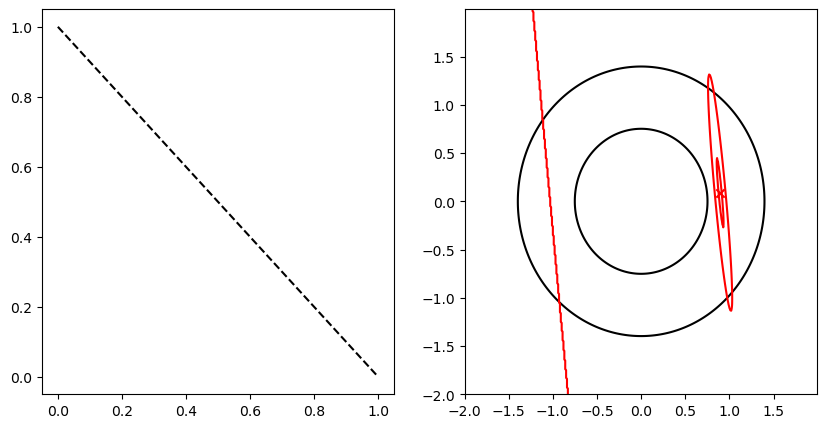

In [ ]:
W_NATURE = np.array([1.0, -1.0])
SIGMA = 0.05
COVARIANCE = np.array([[1.0, 0.0], [0.0, 1.0]])


def model(X: np.ndarray, w: np.ndarray = W_NATURE):
    """
    Model function that computes the output based on input x and weights w.
    """
    return X.T @ w

def measure(X: np.ndarray, w: np.ndarray = W_NATURE, sigma: float = SIGMA):
    """
    Measure function that computes the output based on input x and weights w,
    adding Gaussian noise.
    """
    return model(X, w) + ss.multivariate_normal.rvs(mean=np.zeros(X.shape[1]), cov=SIGMA**2 * np.identity(X.shape[1]))

def generate_1dX(x: np.ndarray, order: int = 2):
    """
    Generate a 1D input array for the model.
    """
    if len(x) == 0:
        return np.array([])
    vectors = [x**i for i in range(order)]
    return np.hstack(vectors).T

def calc_A(X: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    """
    Calculate matrix A
    """
    if len(X) == 0:
        return np.linalg.inv(cov)
    return sigma**(-2) * X @ X.T + np.linalg.inv(cov)

def get_posterior_dist(X: np.ndarray, y: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    """
    Get the posterior distribution of weights w given measurements y.
    """
    if len(y) == 0:
        return ss.multivariate_normal(mean=np.zeros(len(W_NATURE)), cov=COVARIANCE)

    assert len(y) == X.shape[1], f"X.shape[1] = {X.shape[1]} != y.shape[0] = {len(y)}"

    A = calc_A(X, cov, sigma)
    A_inv = np.linalg.inv(A)
    m = A_inv @ X @ y / sigma**2
    return ss.multivariate_normal(mean=m, cov=A_inv)

def get_pfstar_mean(xstar: np.ndarray, X: np.ndarray, y: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    if len(X) == 0:
        return np.zeros_like(xstar)
    A = calc_A(X, cov, sigma)
    A_inv = np.linalg.inv(A)
    vec = A_inv @ X @ y
    return np.dot(xstar.T,  vec) / sigma**2

#def get_pfstar_var(xstar: np.ndarray, X: np.ndarray, y: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
#    A = calc_A(X, cov, sigma)
#    A_inv = np.linalg.inv(A)
#    return xstar.T @ A_inv @ xstar

def get_pfstar_var(xstar: np.ndarray, X: np.ndarray, y: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    A = calc_A(X, cov, sigma)
    A_inv = np.linalg.inv(A)

    # Ensure xstar is 2D
    if xstar.ndim == 1:
        xstar = xstar.reshape(1, -1)

    # Use einsum for efficient batch quadratic form
    results = np.einsum('ni,ij,jn->n', xstar.T, A_inv, xstar)
    
    return results

def get_pfstar_dist(xstar: np.ndarray, X: np.ndarray, y: np.ndarray, cov: np.ndarray = COVARIANCE, sigma: float = SIGMA):
    """
    Get the posterior distribution of weights w given measurements y and a new input xstar.
    """
    m = get_pfstar_mean(xstar, X, y, cov, sigma)
    var = get_pfstar_var(xstar, X, y, cov, sigma)
    return ss.norm(loc=m, scale=var)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
# Plot the prior distribution
w0, w1 = np.mgrid[-2:2:.01, -2:2:.01]
pos = np.dstack((w0, w1))
prior = ss.multivariate_normal(mean=np.zeros(2), cov=COVARIANCE)
ax2.contour(w0, w1, prior.pdf(pos), levels=2, colors='black')

x = np.linspace(0, 1, 100)
X = np.array([np.ones_like(x), x])
ax1.plot(X[1], model(X), linestyle='--', label='modelo', color='black')

n = 10
#x1s = ss.uniform(0, 1).rvs(n).reshape(-1, 1)
x1s = np.array([0.1]).reshape(-1, 1)
X = generate_1dX(x1s, order=len(W_NATURE))
y = measure(X)

posterior = get_posterior_dist(X, y)
ax2.contour(w0, w1, posterior.pdf(pos), levels=2, colors='red')
ax2.scatter(posterior.mean[0], posterior.mean[1], label=f'w0={posterior.mean[0]:.2f}$\pm${posterior.cov[0][0]:.2f}, w1={posterior.mean[1]:.2f}$\pm${posterior.cov[1][1]:.2f}', color='red', marker='x')

#ax1.scatter(X[1], y, label='mediciones')

xm = generate_1dX(np.linspace(0, 1, 100).reshape(-1, 1)) 
means = get_pfstar_mean(xm, X, y)
vars = get_pfstar_var(xm, X, y)
print(vars.shape)
xs = np.linspace(0, 1, 100)
yplus = []
yminus = []
ymean = []
for x in xs:
    x = np.array([1, x]).reshape(-1, 1)
    pfstar = get_pfstar_dist(x, X, y)
    mean, var = pfstar.mean()[0][0], pfstar.std()[0][0]
    std = np.sqrt(var)
    yplus.append(mean + std)
    yminus.append(mean - std)
    ymean.append(mean)



print(means)
ax1.plot(xm[1, :], means, label='mean', color='blue')
ax1.fill_between(xm[1, :], y1=-np.sqrt(vars[1, :]), y2=np.sqrt(vars[1, :]), label='$\pm \sigma$', color='blue', alpha=0.2)

ax1.set_title('Distribution in real space')
ax1.set_ylabel('y')
ax1.set_xlabel('x')
ax1.legend()

ax2.set_ylabel('w1')
ax2.set_xlabel('w0')
ax2.set_title('Distribution in w space')
ax2.set_xlim(-2, 2)
ax2.set_ylim(-2, 2)
ax2.set_aspect('equal')

ax1.grid()
ax2.legend()
plt.tight_layout()
fig.show()